# RAS 585 - Assignment 1 (Fall 2026): AI-generated version
Raisin dataset: Bayesian classification (Parts 1 and 2) and regression / PCA (Part 3).

**Requirements:** numpy, pandas, scipy, matplotlib, scikit-learn, statsmodels.
Expects `Raisin_Dataset.csv` in the same folder as this notebook. Output CSVs are written to the same folder.
Run all cells from top to bottom.

In [31]:
# =============================================================================
# IMPORTS AND SETTINGS
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# COMPARISON WITH MY CODE: The AI version imports statsmodels for OLS summaries and VIF;
#   my version uses scikit-learn LinearRegression and reports prediction metrics directly.

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(42)  # reproducibility for sample generation / CV
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


In [32]:
# =============================================================================
# DATA LOADING
# =============================================================================
df = pd.read_csv("Raisin_Dataset/Raisin_Dataset/Raisin_Dataset.csv")

FEATURES = ["Area", "MajorAxisLength", "MinorAxisLength", "Eccentricity",
            "ConvexArea", "Extent", "Perimeter"]
LABEL = "Class"

X = df[FEATURES].values
y = df[LABEL].values
classes = sorted(df[LABEL].unique())  # alphabetical: ['Besni', 'Kecimen']
K = len(classes)
d = len(FEATURES)
# COMPARISON WITH MY CODE: The AI stores X/y as NumPy arrays and centralizes feature/class names;
#   my version keeps X/y as pandas objects and creates Besni/Kecimen subsets explicitly.
# COMPARISON WITH MY CODE: Both versions treat Besni as the positive class in Part 2, but the AI
#   makes that choice explicit with POSITIVE_CLASS instead of relying on confusion-matrix ordering.

POSITIVE_CLASS = "Besni"  # positive class for TPR/FPR/etc. (Part 2 Q4)
df.head()


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [ ]:
# =============================================================================
# HELPER FUNCTIONS (used throughout Parts 1 and 2)
# =============================================================================

# COMPARISON WITH MY CODE: The AI factors repeated class statistics and discriminant logic into
#   general helper functions for any class list; my Classifier is written specifically for Besni/Kecimen.

def class_stats(X, y, classes):
    """Per-class prior, mean vector, covariance matrix (unbiased, N-1)."""
    priors, means, covs = [], [], []
    for c in classes:
        Xc = X[y == c]
        priors.append(len(Xc) / len(X))
        means.append(Xc.mean(axis=0))
        covs.append(np.cov(Xc, rowvar=False))
    return np.array(priors), np.array(means), np.array(covs)

def quadratic_discriminants(X, priors, means, covs):
    """
    Separate covariance per class (Alpaydin Eq. 5.17 / 4.20 style):
    g_i(x) = -1/2 log|S_i| - 1/2 (x-m_i)^T S_i^-1 (x-m_i) + log P(C_i)
    (the constant -d/2 log(2*pi) is shared by all classes and dropped)
    Returns an (n_samples, K) matrix of discriminant values.
    """
    G = np.zeros((len(X), len(priors)))
    for i in range(len(priors)):
        diff = X - means[i]
        sol = np.linalg.solve(covs[i], diff.T).T
        maha = np.sum(diff * sol, axis=1)
        _, logdet = np.linalg.slogdet(covs[i])
        G[:, i] = -0.5 * logdet - 0.5 * maha + np.log(priors[i])
    return G

def pooled_covariance(priors, covs):
    """Shared covariance: S = sum_i P(C_i) S_i  (Alpaydin Eq. 5.21)."""
    return np.sum(priors[:, None, None] * covs, axis=0)


def linear_discriminants(X, priors, means, S):
    """
    Pooled (shared) covariance (Alpaydin Eq. 5.22 before expanding):
    g_i(x) = -1/2 (x-m_i)^T S^-1 (x-m_i) + log P(C_i)
    (the -1/2 log|S| term is identical for all classes and dropped)
    """
    # slightly different implementation of equation
    G = np.zeros((len(X), len(priors)))
    for i in range(len(priors)):
        diff = X - means[i]
        sol = np.linalg.solve(S, diff.T).T
        G[:, i] = -0.5 * np.sum(diff * sol, axis=1) + np.log(priors[i])
    return G

def labels_from_discriminants(G, classes):
    """Assign the class with the largest discriminant value."""
    return np.array(classes)[np.argmax(G, axis=1)]

def confusion_matrix_df(y_true, y_pred, classes):
    """Confusion matrix; rows = true class, columns = predicted class."""
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    idx = {c: i for i, c in enumerate(classes)}
    for t, p in zip(y_true, y_pred):
        cm[idx[t], idx[p]] += 1
    return pd.DataFrame(cm, index=[f"True {c}" for c in classes],
                        columns=[f"Pred {c}" for c in classes])

# COMPARISON WITH MY CODE: The AI locates TP/FN/FP/TN by class name, which is robust to class order;
#   my get_rates() unpacks cm.ravel(), which is shorter but depends on a deliberate label ordering.

def binary_rates(cm_df, classes, positive):
    """TPR, FPR, TNR, FNR from a 2x2 confusion matrix."""
    cm = cm_df.values
    p = classes.index(positive)
    n = 1 - p
    TP, FN = cm[p, p], cm[p, n]
    FP, TN = cm[n, p], cm[n, n]
    return {"TPR": TP / (TP + FN), "FPR": FP / (FP + TN),
            "TNR": TN / (TN + FP), "FNR": FN / (FN + TP)}


# PART 1

In [34]:
# -----------------------------------------------------------------------------
# Part 1, Q1: What are the classes in this dataset?
# -----------------------------------------------------------------------------
print("Classes:", classes)
print(df[LABEL].value_counts().to_string())


Classes: ['Besni', 'Kecimen']
Class
Kecimen    450
Besni      450


In [35]:
# -----------------------------------------------------------------------------
# Part 1, Q2: Class-prior log odds and discriminant function in terms of log odds
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both compute priors and log prior odds the same way; the AI reuses
#   class_stats(), while my notebook calculates the Besni and Kecimen counts/priors directly.

priors, means, covs = class_stats(X, y, classes)  
C1, C2 = classes[0], classes[1]
prior_log_odds = np.log(priors[0] / priors[1]) 
print(f"P({C1}) = {priors[0]:.4f},  P({C2}) = {priors[1]:.4f}")
print(f"Prior log odds = log[P({C1})/P({C2})] = {prior_log_odds:.4f}")
print("Discriminant function in terms of log odds:")
print(f"  g(x) = log[P({C1}|x)/P({C2}|x)] = log[p(x|{C1})/p(x|{C2})] + log[P({C1})/P({C2})]")
print(f"  Choose {C1} if g(x) > 0, otherwise choose {C2}.")


P(Besni) = 0.5000,  P(Kecimen) = 0.5000
Prior log odds = log[P(Besni)/P(Kecimen)] = 0.0000
Discriminant function in terms of log odds:
  g(x) = log[P(Besni|x)/P(Kecimen|x)] = log[p(x|Besni)/p(x|Kecimen)] + log[P(Besni)/P(Kecimen)]
  Choose Besni if g(x) > 0, otherwise choose Kecimen.


In [36]:
# -----------------------------------------------------------------------------
# Part 1, Q3: Mean vector and covariance matrix per class (multivariate normal)
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both use np.cov(..., rowvar=False); the AI loops over classes and
#   prints full vectors/matrices, while my version computes Besni and Kecimen separately.

for i, c in enumerate(classes):
    print(f"\nClass: {c}")
    print("Mean vector:")
    print(pd.Series(means[i], index=FEATURES).to_string())
    print("Covariance matrix:")
    print(pd.DataFrame(covs[i], index=FEATURES, columns=FEATURES).to_string())



Class: Besni
Mean vector:
Area               112194.788889
MajorAxisLength       509.000652
MinorAxisLength       279.623674
Eccentricity            0.821125
ConvexArea         116675.824444
Extent                  0.691242
Perimeter            1348.127036
Covariance matrix:
                         Area  MajorAxisLength  MinorAxisLength  Eccentricity    ConvexArea      Extent     Perimeter
Area             1.538985e+09     3.686536e+06     1.783472e+06    312.843878  1.590357e+09  349.850895  9.096330e+06
MajorAxisLength  3.686536e+06     1.118754e+04     3.337312e+03      3.534594  3.924327e+06   -0.718686  2.513957e+04
MinorAxisLength  1.783472e+06     3.337312e+03     2.576949e+03     -1.037589  1.824379e+06    0.891603  9.625067e+03
Eccentricity     3.128439e+02     3.534594e+00    -1.037589e+00      0.004662  3.772094e+02   -0.001346  4.771912e+00
ConvexArea       1.590357e+09     3.924327e+06     1.824379e+06    377.209355  1.664401e+09  231.806348  9.719713e+06
Extent         

In [37]:
# -----------------------------------------------------------------------------
# Part 1, Q4: Generate 20 samples from each class's multivariate distribution
# -----------------------------------------------------------------------------

# COMPARISON WITH MY CODE: Both sample with np.random.multivariate_normal using the fitted mean
#   and covariance. The AI loops over classes, combines all samples, and saves them to CSV;
#   my version generates and displays the two classes separately.

generated = []
for i, c in enumerate(classes):
    s = np.random.multivariate_normal(means[i], covs[i], size=20) 
    s_df = pd.DataFrame(s, columns=FEATURES)
    s_df[LABEL] = c
    generated.append(s_df)
generated_df = pd.concat(generated, ignore_index=True)
generated_df.to_csv("part1_q4_generated_samples.csv", index=False)
print(f"Generated {len(generated_df)} samples (20 x {K} classes). "
      f"Saved to part1_q4_generated_samples.csv")
generated_df.head()


Generated 40 samples (20 x 2 classes). Saved to part1_q4_generated_samples.csv


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,92425.742952,470.892557,261.617935,0.854925,96744.553036,0.669516,1291.653795,Besni
1,81064.422296,470.320735,224.036035,0.817593,86445.881021,0.651629,1211.684036,Besni
2,178458.720964,636.957554,370.724166,0.824198,188184.010699,0.771852,1746.296026,Besni
3,121190.653603,479.691496,309.891335,0.769327,125726.086069,0.784842,1324.830863,Besni
4,135049.019007,525.842866,337.651294,0.769860,141787.051409,0.740986,1507.202892,Besni


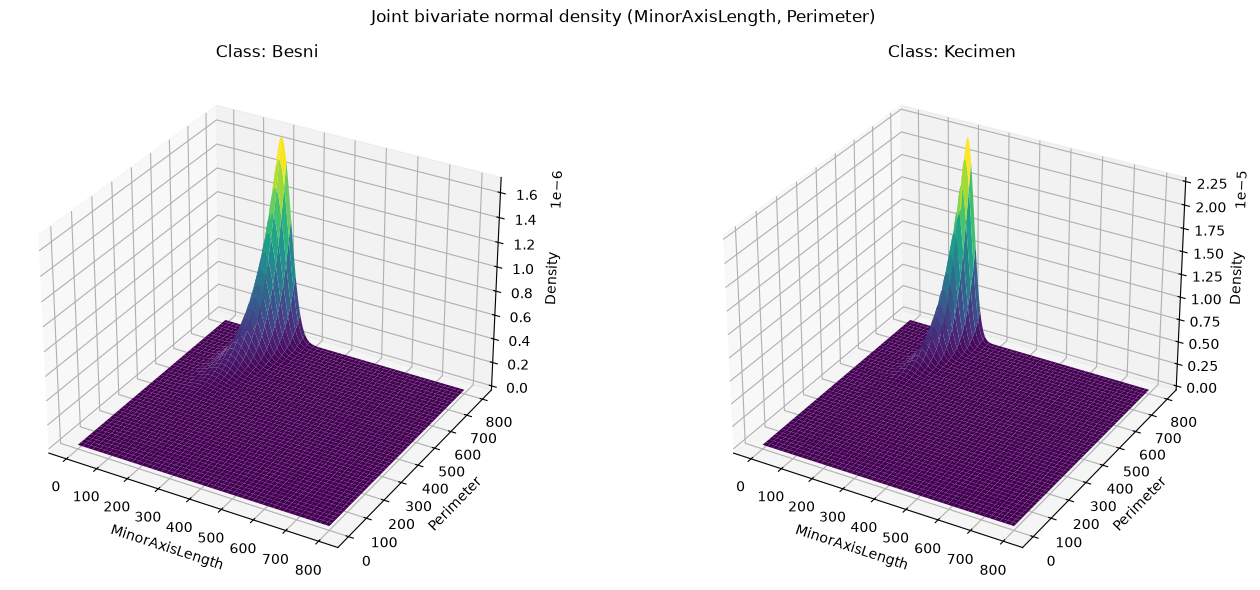

Are MinorAxisLength and Perimeter each univariate normal?
  Yes. Under the multivariate normal assumption, every marginal (and every
  linear combination) of the variables is univariate normal, with mean equal
  to the corresponding entry of the mean vector and variance equal to the
  corresponding diagonal entry of the covariance matrix. (This is a property
  of the assumed model; whether the real data actually is normal would need
  to be checked separately, e.g., with histograms / Q-Q plots.)


In [38]:
# -----------------------------------------------------------------------------
# Part 1, Q5: Visualize joint distribution of MinorAxisLength & Perimeter per class
# -----------------------------------------------------------------------------

# COMPARISON WITH MY CODE: Both form a 2-D Gaussian from MinorAxisLength and Perimeter and evaluate
#   it on a meshgrid. My version also shows seaborn jointplots of the observed data before the
#   density surfaces; the AI focuses on the fitted Gaussian density and handles both classes in one loop.

ix = [FEATURES.index("MinorAxisLength"), FEATURES.index("Perimeter")]

grid_pts = np.linspace(0, 800, 200)
GX, GY = np.meshgrid(grid_pts, grid_pts)
grid = np.dstack((GX, GY))  # shape (200, 200, 2)

fig = plt.figure(figsize=(14, 6))

for i, c in enumerate(classes):
    # Marginal of a multivariate normal over a subset of variables is again
    # multivariate normal: take sub-vector of mean and sub-matrix of covariance.
    mu2 = means[i][ix]
    cov2 = covs[i][np.ix_(ix, ix)]
    Z = multivariate_normal(mean=mu2, cov=cov2).pdf(grid)
    ax = fig.add_subplot(1, K, i + 1, projection="3d")
    ax.plot_surface(GX, GY, Z, cmap="viridis", linewidth=0, antialiased=True)
    ax.set_xlabel("MinorAxisLength")
    ax.set_ylabel("Perimeter")
    ax.set_zlabel("Density")
    ax.set_title(f"Class: {c}")
plt.suptitle("Joint bivariate normal density (MinorAxisLength, Perimeter)")
plt.tight_layout()
plt.show()

print("Are MinorAxisLength and Perimeter each univariate normal?")
print("  Yes. Under the multivariate normal assumption, every marginal (and every")
print("  linear combination) of the variables is univariate normal, with mean equal")
print("  to the corresponding entry of the mean vector and variance equal to the")
print("  corresponding diagonal entry of the covariance matrix. (This is a property")
print("  of the assumed model; whether the real data actually is normal would need")
print("  to be checked separately, e.g., with histograms / Q-Q plots.)")


In [39]:
# -----------------------------------------------------------------------------
# Part 1, Q6: Functional form of the likelihood ratio
# -----------------------------------------------------------------------------
print("Notation: m_i = mean vector of class i, S_i = covariance of class i, d = #features")
print("  p(x|C_i) = (2*pi)^(-d/2) |S_i|^(-1/2) exp{ -1/2 (x-m_i)^T S_i^-1 (x-m_i) }")
print(f"  LR(x) = p(x|{C1}) / p(x|{C2})")
print(f"        = (|S_{C2}|/|S_{C1}|)^(1/2) * exp{{ -1/2 [ (x-m_{C1})^T S_{C1}^-1 (x-m_{C1})")
print(f"                                        - (x-m_{C2})^T S_{C2}^-1 (x-m_{C2}) ] }}")
print("  log LR(x) = 1/2 log|S2| - 1/2 log|S1| - 1/2[(x-m1)^T S1^-1 (x-m1) - (x-m2)^T S2^-1 (x-m2)]")


Notation: m_i = mean vector of class i, S_i = covariance of class i, d = #features
  p(x|C_i) = (2*pi)^(-d/2) |S_i|^(-1/2) exp{ -1/2 (x-m_i)^T S_i^-1 (x-m_i) }
  LR(x) = p(x|Besni) / p(x|Kecimen)
        = (|S_Kecimen|/|S_Besni|)^(1/2) * exp{ -1/2 [ (x-m_Besni)^T S_Besni^-1 (x-m_Besni)
                                        - (x-m_Kecimen)^T S_Kecimen^-1 (x-m_Kecimen) ] }
  log LR(x) = 1/2 log|S2| - 1/2 log|S1| - 1/2[(x-m1)^T S1^-1 (x-m1) - (x-m2)^T S2^-1 (x-m2)]


In [40]:
# -----------------------------------------------------------------------------
# Part 1, Q7: Discriminant function per class (separate covariances), label samples
# -----------------------------------------------------------------------------
print("  g_i(x) = -1/2 log|S_i| - 1/2 (x-m_i)^T S_i^-1 (x-m_i) + log P(C_i)")
# COMPARISON WITH MY CODE: The main functional difference is organization. My Classifier stores
#   class parameters and predicts one sample at a time; the AI computes vectorized discriminant scores
#   for all samples and supports an arbitrary number of classes. Both now use the textbook quadratic form.

G_quad = quadratic_discriminants(X, priors, means, covs)
pred_quad = labels_from_discriminants(G_quad, classes)


q7_df = df.copy()
for i, c in enumerate(classes):
    q7_df[f"g_{c}"] = G_quad[:, i]
q7_df["PredictedClass"] = pred_quad
q7_df.to_csv("part1_q7_labels_separate_cov.csv", index=False)
print("Labels saved to part1_q7_labels_separate_cov.csv")
q7_df[[f"g_{c}" for c in classes] + [LABEL, "PredictedClass"]].head()


  g_i(x) = -1/2 log|S_i| - 1/2 (x-m_i)^T S_i^-1 (x-m_i) + log P(C_i)
Labels saved to part1_q7_labels_separate_cov.csv


,g_Besni,g_Kecimen,Class,PredictedClass
0,-23.347978,-23.093578,Kecimen,Kecimen
1,-22.716455,-20.188648,Kecimen,Kecimen
2,-23.290682,-22.882351,Kecimen,Kecimen
3,-31.994368,-19.917548,Kecimen,Kecimen
4,-38.554094,-22.643950,Kecimen,Kecimen


In [41]:
# -----------------------------------------------------------------------------
# Part 1, Q8: Discriminant function per class (pooled covariance), label samples
# -----------------------------------------------------------------------------

# COMPARISON WITH MY CODE: Both construct the pooled covariance as the prior-weighted class
#   covariances. My Classifier switches between pooled/non-pooled covariance with a flag; the AI uses
#   a separate linear_discriminants() function and drops terms shared by all classes.

S_pooled = pooled_covariance(priors, covs)
print("  S = sum_i P(C_i) S_i")
print("  g_i(x) = -1/2 (x-m_i)^T S^-1 (x-m_i) + log P(C_i)")
G_lin = linear_discriminants(X, priors, means, S_pooled)
pred_lin = labels_from_discriminants(G_lin, classes)

q8_df = df.copy()
for i, c in enumerate(classes):
    q8_df[f"g_{c}"] = G_lin[:, i]
q8_df["PredictedClass"] = pred_lin
q8_df.to_csv("part1_q8_labels_pooled_cov.csv", index=False)
print("Labels saved to part1_q8_labels_pooled_cov.csv")
q8_df[[f"g_{c}" for c in classes] + [LABEL, "PredictedClass"]].head()


  S = sum_i P(C_i) S_i
  g_i(x) = -1/2 (x-m_i)^T S^-1 (x-m_i) + log P(C_i)
Labels saved to part1_q8_labels_pooled_cov.csv


,g_Besni,g_Kecimen,Class,PredictedClass
0,-2.359821,-3.142419,Kecimen,Besni
1,-1.702780,-1.897708,Kecimen,Besni
2,-2.295050,-3.531983,Kecimen,Besni
3,-5.600293,-1.742571,Kecimen,Kecimen
4,-7.493993,-5.470977,Kecimen,Kecimen


In [42]:
# -----------------------------------------------------------------------------
# Part 1, Q9: Confusion matrices and accuracy for Q7 and Q8
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: My version uses sklearn's confusion_matrix/ConfusionMatrixDisplay;
#   the AI builds a labeled confusion matrix manually. Accuracy is computed equivalently in both.

cm_quad = confusion_matrix_df(y, pred_quad, classes)
cm_lin = confusion_matrix_df(y, pred_lin, classes)
acc_quad = np.mean(pred_quad == y)
acc_lin = np.mean(pred_lin == y)

print("Q7: Separate covariance matrices (quadratic)")
print(cm_quad.to_string())
print(f"Accuracy = {acc_quad:.4f}")
print("\nQ8: Pooled covariance matrix (linear)")
print(cm_lin.to_string())
print(f"Accuracy = {acc_lin:.4f}")
better = "separate covariance (Q7)" if acc_quad > acc_lin else (
    "pooled covariance (Q8)" if acc_lin > acc_quad else "neither (tie)")
print(f"\nFinding: higher accuracy on the full dataset -> {better}.")
print("Note: both are evaluated on the same data used to estimate the parameters")
print("(training accuracy), so the more flexible model (separate covariances) has an")
print("advantage; Part 2 uses cross-validation for a fairer comparison.")


Q7: Separate covariance matrices (quadratic)
              Pred Besni  Pred Kecimen
True Besni           344           106
True Kecimen          20           430
Accuracy = 0.8600

Q8: Pooled covariance matrix (linear)
              Pred Besni  Pred Kecimen
True Besni           382            68
True Kecimen          58           392
Accuracy = 0.8600

Finding: higher accuracy on the full dataset -> neither (tie).
Note: both are evaluated on the same data used to estimate the parameters
(training accuracy), so the more flexible model (separate covariances) has an
advantage; Part 2 uses cross-validation for a fairer comparison.


# PART 2: 5-fold cross-validation

In [ ]:
# -----------------------------------------------------------------------------
# Part 2, Q1-Q3: per fold -> class means/covariances (Q1), separate-covariance
# discriminant + confusion matrix (Q2), pooled-covariance discriminant +
# confusion matrix (Q3)
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both use the same 5-fold KFold settings and refit class parameters only
#   on each training fold before predicting the test fold. The AI performs Q1-Q3 in one loop and saves
#   every fold's predictions to CSV; my version stores confusion matrices/accuracies for later averaging.

kf = KFold(n_splits=5, shuffle=True, random_state=42) #also uses Kfold

fold_rates_quad, fold_rates_lin = [], []
fold_acc_quad, fold_acc_lin = [], []
all_fold_labels = []

for fold, (tr_idx, te_idx) in enumerate(kf.split(X), start=1):
    print(f"\n{'-' * 30} Fold {fold} {'-' * 30}")
    X_tr, y_tr = X[tr_idx], y[tr_idx]
    X_te, y_te = X[te_idx], y[te_idx]

    # ---- Part 2, Q1: mean vector and covariance matrix per class (training data)
    print(f"[Part 2, Q1 | Fold {fold}] Class means and covariances (training data)")
    pri_f, mu_f, cov_f = class_stats(X_tr, y_tr, classes)
    for i, c in enumerate(classes):
        print(f"\nClass {c} (prior = {pri_f[i]:.4f})")
        print("Mean:")
        print(pd.Series(mu_f[i], index=FEATURES).to_string())
        print("Covariance:")
        print(pd.DataFrame(cov_f[i], index=FEATURES, columns=FEATURES).to_string())

    # ---- Part 2, Q2: discriminant (separate covariances) -> labels -> confusion matrix
    G_q = quadratic_discriminants(X_te, pri_f, mu_f, cov_f)
    pred_q = labels_from_discriminants(G_q, classes)
    cm_q = confusion_matrix_df(y_te, pred_q, classes)
    acc_q = np.mean(pred_q == y_te)
    print(f"\n[Part 2, Q2 | Fold {fold}] Separate covariance - confusion matrix (test)")
    print(cm_q.to_string())
    print(f"Accuracy = {acc_q:.4f}")

    # ---- Part 2, Q3: discriminant (pooled covariance) -> labels -> confusion matrix
    S_f = pooled_covariance(pri_f, cov_f)
    G_l = linear_discriminants(X_te, pri_f, mu_f, S_f)
    pred_l = labels_from_discriminants(G_l, classes)
    cm_l = confusion_matrix_df(y_te, pred_l, classes)
    acc_l = np.mean(pred_l == y_te)
    print(f"\n[Part 2, Q3 | Fold {fold}] Pooled covariance - confusion matrix (test)")
    print(cm_l.to_string())
    print(f"Accuracy = {acc_l:.4f}")

    # Store labels for this fold (saved to a single CSV after the loop)
    fold_df = df.iloc[te_idx].copy()
    fold_df["Fold"] = fold
    fold_df["Pred_SeparateCov"] = pred_q
    fold_df["Pred_PooledCov"] = pred_l
    all_fold_labels.append(fold_df)

    # Collect rates for Q4
    fold_rates_quad.append(binary_rates(cm_q, classes, POSITIVE_CLASS))
    fold_rates_lin.append(binary_rates(cm_l, classes, POSITIVE_CLASS))
    fold_acc_quad.append(acc_q)
    fold_acc_lin.append(acc_l)

pd.concat(all_fold_labels).to_csv("part2_cv_labels.csv", index=False)
print("\nTest labels for all folds saved to part2_cv_labels.csv")



------------------------------ Fold 1 ------------------------------
[Part 2, Q1 | Fold 1] Class means and covariances (training data)

Class Besni (prior = 0.5056)
Mean:
Area               112271.335165
MajorAxisLength       508.864838
MinorAxisLength       279.700944
Eccentricity            0.820628
ConvexArea         116719.648352
Extent                  0.689467
Perimeter            1347.951676
Covariance:
                         Area  MajorAxisLength  MinorAxisLength  Eccentricity    ConvexArea      Extent     Perimeter
Area             1.571430e+09     3.736152e+06     1.818471e+06    305.803267  1.614736e+09  349.698288  9.170780e+06
MajorAxisLength  3.736152e+06     1.121307e+04     3.372328e+03      3.578979  3.938327e+06   -0.775385  2.497014e+04
MinorAxisLength  1.818471e+06     3.372328e+03     2.631157e+03     -1.109618  1.850720e+06    0.911929  9.707409e+03
Eccentricity     3.058033e+02     3.578979e+00    -1.109618e+00      0.004933  3.643960e+02   -0.001453  4.696186

In [ ]:
# -----------------------------------------------------------------------------
# Part 2, Q4: Average TPR, FPR, TNR, FNR across the five folds (positive = Besni)
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both average rates across the five fold-specific confusion matrices.
#   The AI indexes the positive class by name; my get_rates() uses tn, fp, fn, tp = cm.ravel(), so my
#   confusion-matrix label order must place Besni second for Besni to be the positive class.

print(f"Positive class = {POSITIVE_CLASS}")
rates_quad_df = pd.DataFrame(fold_rates_quad, index=[f"Fold {i}" for i in range(1, 6)])
rates_lin_df = pd.DataFrame(fold_rates_lin, index=[f"Fold {i}" for i in range(1, 6)])
print("\nSeparate covariance (per-fold rates):")
print(rates_quad_df.round(4).to_string())
print("Average:")
print(rates_quad_df.mean().round(4).to_string())
print("\nPooled covariance (per-fold rates):")
print(rates_lin_df.round(4).to_string())
print("Average:")
print(rates_lin_df.mean().round(4).to_string())


Positive class = Besni

Separate covariance (per-fold rates):
           TPR     FPR     TNR     FNR
Fold 1  0.7674  0.0745  0.9255  0.2326
Fold 2  0.7590  0.1237  0.8763  0.2410
Fold 3  0.7412  0.0316  0.9684  0.2588
Fold 4  0.7525  0.0127  0.9873  0.2475
Fold 5  0.7579  0.0235  0.9765  0.2421
Average:
TPR    0.7556
FPR    0.0532
TNR    0.9468
FNR    0.2444

Pooled covariance (per-fold rates):
           TPR     FPR     TNR     FNR
Fold 1  0.8837  0.1489  0.8511  0.1163
Fold 2  0.8675  0.1649  0.8351  0.1325
Fold 3  0.8235  0.1158  0.8842  0.1765
Fold 4  0.8020  0.1392  0.8608  0.1980
Fold 5  0.8632  0.0824  0.9176  0.1368
Average:
TPR    0.8480
FPR    0.1303
TNR    0.8697
FNR    0.1520


In [ ]:
# -----------------------------------------------------------------------------
# Part 2, Q5: Performance summary and best method
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both reach the same model-selection conclusion from average CV accuracy;
#   the AI packages accuracy and class rates into one summary table, while my version prints them separately.

summary = pd.DataFrame({
    "Separate covariance": {**rates_quad_df.mean().to_dict(),
                            "Accuracy": np.mean(fold_acc_quad)},
    "Pooled covariance": {**rates_lin_df.mean().to_dict(),
                          "Accuracy": np.mean(fold_acc_lin)},
}).round(4)
print(summary.to_string())
best = summary.loc["Accuracy"].idxmax()
print(f"\nBest method by average CV accuracy: {best}")
print("(Also compare TPR/TNR above: a higher TPR and TNR with lower FPR and FNR is better.)")



          Separate covariance  Pooled covariance
TPR                    0.7556             0.8480
FPR                    0.0532             0.1303
TNR                    0.9468             0.8697
FNR                    0.2444             0.1520
Accuracy               0.8500             0.8578

Best method by average CV accuracy: Pooled covariance
(Also compare TPR/TNR above: a higher TPR and TNR with lower FPR and FNR is better.)


# PART 3: Regression and PCA (dependent variable = Perimeter)

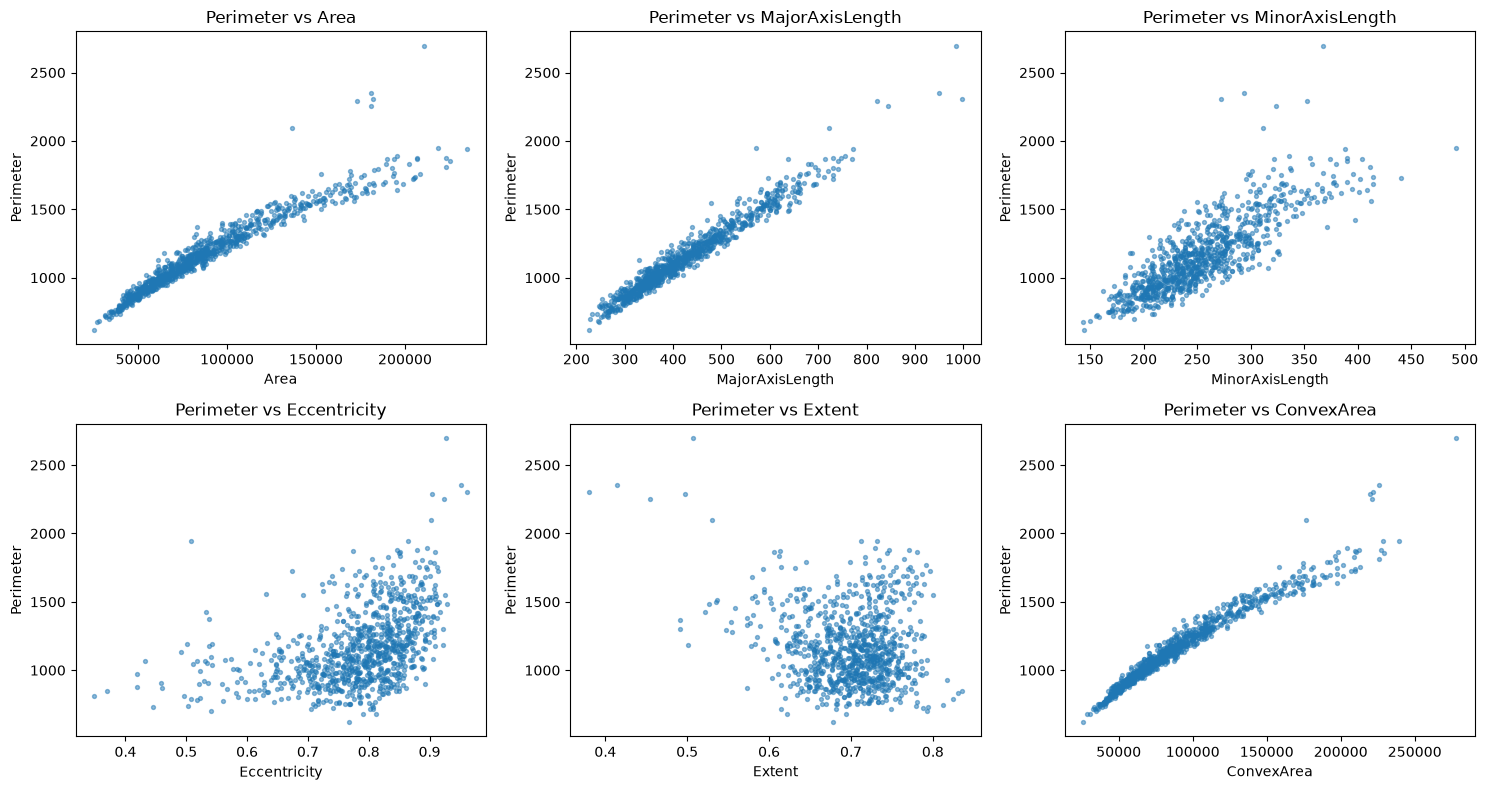

Describe trends in the report (e.g., strength/direction/linearity per plot).


In [ ]:
# -----------------------------------------------------------------------------
# Part 3, Q1: Scatter plots of Perimeter vs each independent variable (6 plots)
# -----------------------------------------------------------------------------
IND_VARS = ["Area", "MajorAxisLength", "MinorAxisLength", "Eccentricity",
            "Extent", "ConvexArea"]
DEP_VAR = "Perimeter"

# COMPARISON WITH MY CODE: Both loop over the same six predictors and plot Perimeter against each one;
#   differences here are only plotting/layout choices.

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.ravel(), IND_VARS):
    ax.scatter(df[var], df[DEP_VAR], s=8, alpha=0.5)
    ax.set_xlabel(var)
    ax.set_ylabel(DEP_VAR)
    ax.set_title(f"{DEP_VAR} vs {var}")
plt.tight_layout()
plt.show()
print("Describe trends in the report (e.g., strength/direction/linearity per plot).")


In [ ]:
# -----------------------------------------------------------------------------
# Part 3, Q2: Correlation matrix on training data (first 700 samples)
# -----------------------------------------------------------------------------
train = df.iloc[:700]
test = df.iloc[700:]
X_train, y_train = train[IND_VARS], train[DEP_VAR]
X_test, y_test = test[IND_VARS], test[DEP_VAR]

# COMPARISON WITH MY CODE: Both correctly compute correlation from the first 700 training samples.
#   My version visualizes the full matrix as a seaborn heatmap; the AI prints the matrix and additionally
#   sorts each predictor by absolute correlation with Perimeter.

corr = train[IND_VARS + [DEP_VAR]].corr()
corr.to_csv("part3_q2_correlation_matrix.csv")
print(corr.round(4).to_string())
print("\nCorrelation of each independent variable with Perimeter (sorted by |r|):")
print(corr[DEP_VAR].drop(DEP_VAR).sort_values(key=np.abs, ascending=False)
      .round(4).to_string())
print("\nCausality: a strong correlation does NOT by itself imply causation.")
print("Correlation only measures linear co-movement; it cannot rule out confounders,")
print("reverse causation, or a shared cause. Here, Perimeter and the size variables are")
print("all geometric properties of the same raisin (they are mathematically related")
print("descriptors of shape/size), so association reflects geometry, not cause-and-effect.")


                   Area  MajorAxisLength  MinorAxisLength  Eccentricity  Extent  ConvexArea  Perimeter
Area             1.0000           0.9375           0.8964        0.3388 -0.0721      0.9953     0.9632
MajorAxisLength  0.9375           1.0000           0.7213        0.5750 -0.2511      0.9498     0.9791
MinorAxisLength  0.8964           0.7213           1.0000       -0.0452  0.1020      0.8838     0.8201
Eccentricity     0.3388           0.5750          -0.0452        1.0000 -0.3878      0.3512     0.4417
Extent          -0.0721          -0.2511           0.1020       -0.3878  1.0000     -0.1157    -0.2200
ConvexArea       0.9953           0.9498           0.8838        0.3512 -0.1157      1.0000     0.9791
Perimeter        0.9632           0.9791           0.8201        0.4417 -0.2200      0.9791     1.0000

Correlation of each independent variable with Perimeter (sorted by |r|):
ConvexArea         0.9791
MajorAxisLength    0.9791
Area               0.9632
MinorAxisLength    0.820

In [ ]:
# -----------------------------------------------------------------------------
# Part 3, Q3: Fit linear regression on training data and summarize coefficients
# -----------------------------------------------------------------------------

# COMPARISON WITH MY CODE: The AI uses statsmodels OLS so it can report p-values, standard errors, and
#   standardized coefficients. My version uses sklearn LinearRegression and prints raw coefficients only.
#   The AI's standardized coefficients are more appropriate for comparing predictor impact across scales.

X_train_c = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_c).fit()
print(ols_model.summary())

std_coefs = ols_model.params.drop("const") * X_train.std() / y_train.std()
print("\nStandardized coefficients (beta * sd_x / sd_y), sorted by magnitude:")
print(std_coefs.sort_values(key=np.abs, ascending=False).round(4).to_string())
print("Variables with the largest |standardized coefficient| have the greater impact.")
print("(Raw coefficients depend on each variable's units/scale, so compare the")
print("standardized ones; also check p-values in the summary above.)")


                            OLS Regression Results                            
Dep. Variable:              Perimeter   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                 2.441e+04
Date:                Sun, 04 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:40:44   Log-Likelihood:                -3030.3
No. Observations:                 700   AIC:                             6075.
Df Residuals:                     693   BIC:                             6106.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              16.9465     23.414     

In [49]:
# -----------------------------------------------------------------------------
# Part 3, Q4: Predictions on testing data and MSE
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both predict the held-out last 200 samples and compute MSE. My version also
#   plots actual vs. predicted Perimeter and reports sklearn R^2; the AI adds RMSE and variance context.

X_test_c = sm.add_constant(X_test, has_constant="add")
y_pred_ols = ols_model.predict(X_test_c)
mse_ols = mean_squared_error(y_test, y_pred_ols)
print(f"Test MSE = {mse_ols:.4f}   (RMSE = {np.sqrt(mse_ols):.4f})")
print(f"For context: variance of test Perimeter = {y_test.var():.4f}, "
      f"test R^2 = {1 - mse_ols / np.mean((y_test - y_test.mean()) ** 2):.4f}")
print("Judge predictive performance in the report by comparing MSE/RMSE to the scale")
print("and variance of Perimeter.")


Test MSE = 665.9862   (RMSE = 25.8067)
For context: variance of test Perimeter = 56274.4278, test R^2 = 0.9881
Judge predictive performance in the report by comparing MSE/RMSE to the scale
and variance of Perimeter.


In [50]:
# -----------------------------------------------------------------------------
# Part 3, Q5: Are the independent variables mutually linearly independent?
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: My written answer identifies multicollinearity conceptually from overlapping
#   size/shape information. The AI goes further by calculating pairwise correlations and VIF values to
#   quantify the dependence and explain its effect on coefficient stability.

print("Pairwise correlations among independent variables (training data):")
print(corr.loc[IND_VARS, IND_VARS].round(3).to_string())
vif = pd.Series(
    [variance_inflation_factor(X_train_c.values, i + 1) for i in range(len(IND_VARS))],
    index=IND_VARS)
print("\nVariance inflation factors (VIF > 10 suggests serious multicollinearity):")
print(vif.round(2).to_string())
print("\nEffects of linear dependence among predictors on the fitted model:")
print("  - Coefficient estimates become unstable (large variance, sensitive to small")
print("    changes in the data) and may have counterintuitive signs/magnitudes.")
print("  - Standard errors inflate, so individually important variables can look")
print("    statistically insignificant.")
print("  - Individual coefficients are hard to interpret (variables cannot be changed")
print("    independently), although overall predictions can remain fine.")
print("  - Under perfect collinearity X^T X is singular and OLS has no unique solution.")


Pairwise correlations among independent variables (training data):
                  Area  MajorAxisLength  MinorAxisLength  Eccentricity  Extent  ConvexArea
Area             1.000            0.937            0.896         0.339  -0.072       0.995
MajorAxisLength  0.937            1.000            0.721         0.575  -0.251       0.950
MinorAxisLength  0.896            0.721            1.000        -0.045   0.102       0.884
Eccentricity     0.339            0.575           -0.045         1.000  -0.388       0.351
Extent          -0.072           -0.251            0.102        -0.388   1.000      -0.116
ConvexArea       0.995            0.950            0.884         0.351  -0.116       1.000

Variance inflation factors (VIF > 10 suggests serious multicollinearity):
Area               159.91
MajorAxisLength     40.35
MinorAxisLength     19.40
Eccentricity         5.02
Extent               1.50
ConvexArea         189.09

Effects of linear dependence among predictors on the fitted mode

In [ ]:
# -----------------------------------------------------------------------------
# Part 3, Q6: PCA on training independent variables (standardized) + variance explained
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: The PCA pipeline is functionally the same in both versions: fit StandardScaler
#   and PCA on training data only, then use those fitted transforms on the test data to avoid leakage.

scaler = StandardScaler().fit(X_train)          # fit on TRAIN only
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)           # apply train scaling to test


pca = PCA().fit(X_train_std)
var_ratio = pca.explained_variance_ratio_
pc_names = [f"PC{i + 1}" for i in range(len(var_ratio))]
var_table = pd.DataFrame({
    "Eigenvalue (variance)": pca.explained_variance_,
    "Variance explained": var_ratio,
    "Cumulative": np.cumsum(var_ratio),
}, index=pc_names)
print(var_table.round(4).to_string())


     Eigenvalue (variance)  Variance explained  Cumulative
PC1                 3.8641              0.6431      0.6431
PC2                 1.4524              0.2417      0.8848
PC3                 0.6209              0.1033      0.9882
PC4                 0.0541              0.0090      0.9972
PC5                 0.0139              0.0023      0.9995
PC6                 0.0031              0.0005      1.0000


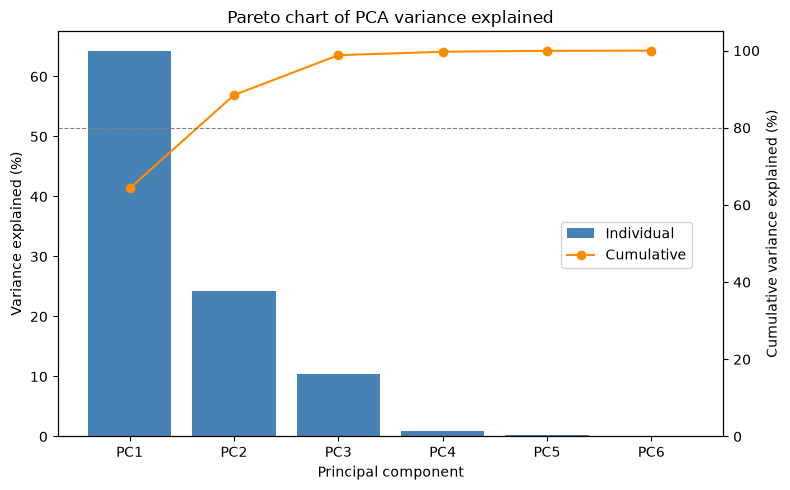

In [52]:
# -----------------------------------------------------------------------------
# Part 3, Q7: Pareto chart of variance explained by each principal component
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both Pareto charts show individual and cumulative explained variance;
#   the AI expresses the values as percentages and adds an 80% reference line.

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(pc_names, var_ratio * 100, color="steelblue", label="Individual")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax2 = ax1.twinx()
ax2.plot(pc_names, np.cumsum(var_ratio) * 100, color="darkorange",
         marker="o", label="Cumulative")
ax2.set_ylabel("Cumulative variance explained (%)")
ax2.set_ylim(0, 105)
ax2.axhline(80, color="gray", linestyle="--", linewidth=0.8)
plt.title("Pareto chart of PCA variance explained")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
plt.tight_layout()
plt.show()


In [ ]:
# -----------------------------------------------------------------------------
# Part 3, Q8: Regression on first four PCs, predict test samples, compute MSE
# -----------------------------------------------------------------------------
# COMPARISON WITH MY CODE: Both regress Perimeter on the first four training PCs and evaluate on transformed
#   test data with MSE. The AI additionally compares PCR MSE with the full OLS model and reports variance retained.

n_pc = 4
Z_train = pca.transform(X_train_std)[:, :n_pc]
Z_test = pca.transform(X_test_std)[:, :n_pc]    # test projected with TRAIN PCA


pcr = LinearRegression().fit(Z_train, y_train)
print("Intercept:", round(pcr.intercept_, 4))
print("Coefficients:", dict(zip(pc_names[:n_pc], np.round(pcr.coef_, 4))))
y_pred_pcr = pcr.predict(Z_test)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)
print(f"Test MSE (4-PC model)       = {mse_pcr:.4f}")
print(f"Test MSE (full OLS, Q4)     = {mse_ols:.4f}")
print(f"Variance retained by 4 PCs  = {np.sum(var_ratio[:n_pc]) * 100:.2f}%")


Intercept: 1121.9481
Coefficients: {'PC1': np.float64(134.4034), 'PC2': np.float64(-7.144), 'PC3': np.float64(-10.3798), 'PC4': np.float64(-88.393)}
Test MSE (4-PC model)       = 1866.2970
Test MSE (full OLS, Q4)     = 665.9862
Variance retained by 4 PCs  = 99.72%


In [54]:
# -----------------------------------------------------------------------------
# Part 3, Q9: Practical scenarios for using / not using PCA before regression
# -----------------------------------------------------------------------------
print("USE PCA: Near-infrared (NIR) spectroscopy for predicting protein content in")
print("  grain. Each sample has hundreds of highly correlated wavelength readings (more")
print("  predictors than samples, severe multicollinearity). PCA compresses them into")
print("  a few uncorrelated components, stabilizing the regression and reducing overfitting.")
print("DO NOT USE PCA: A clinical or policy model (e.g., predicting hospital cost from age,")
print("  smoking status, and number of prior admissions) where each coefficient must be")
print("  interpreted and explained to stakeholders. PCs are mixtures of all variables,")
print("  so effects of the original variables are lost; with few, weakly correlated")
print("  predictors PCA adds complexity with little benefit.")
print("\nDone.")


USE PCA: Near-infrared (NIR) spectroscopy for predicting protein content in
  grain. Each sample has hundreds of highly correlated wavelength readings (more
  predictors than samples, severe multicollinearity). PCA compresses them into
  a few uncorrelated components, stabilizing the regression and reducing overfitting.
DO NOT USE PCA: A clinical or policy model (e.g., predicting hospital cost from age,
  smoking status, and number of prior admissions) where each coefficient must be
  interpreted and explained to stakeholders. PCs are mixtures of all variables,
  so effects of the original variables are lost; with few, weakly correlated
  predictors PCA adds complexity with little benefit.

Done.
